<a href="https://colab.research.google.com/github/aathil28/Computer_Vision_Parallel_Project_Group_2/blob/feature%2Fmodel/Group_2_CNN_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Libraries

In [50]:
import os
import cv2
import numpy as np
from google.colab.patches import cv2_imshow
import matplotlib.pyplot as plt


import tensorflow as tf

In [51]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


#Read Dataset

In [52]:
# Image parameters
IMG_HEIGHT = 224
IMG_WIDTH = 224
BATCH_SIZE = 32

# data path
train_dir = "/content/drive/MyDrive/Datasets/Brain_tumer_dataset_parallel_project/Training"
test_dir = "/content/drive/MyDrive/Datasets/Brain_tumer_dataset_parallel_project/Testing"

In [53]:
# Load train dataset
train_dataset = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE
)

Found 5600 files belonging to 4 classes.


In [54]:
# Validation dataset

validation_dataset = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="validation",
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    seed = 42
)

Found 5600 files belonging to 4 classes.
Using 1120 files for validation.


In [55]:
# Inference: validation dataset used monitor the model while it is learning.

In [56]:
# Load test dataset
test_dataset = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE
)

Found 1600 files belonging to 4 classes.


# EDA

## Class Distribution

In [57]:
# Verifying dataset classes
class_names = train_dataset.class_names
print('classes:', class_names)

classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


In [58]:
# Image count in each class in training dataset
print("Training Dataset")

for cls in class_names:
    count = len(os.listdir(os.path.join(train_dir, cls)))
    print(f"{cls}: {count} images")


print('\n')

# Image count in each class in test dataset
print("Testing Dataset")

for cls in class_names:
    count = len(os.listdir(os.path.join(test_dir, cls)))
    print(f"{cls}: {count} images")

Training Dataset
glioma: 1400 images
meningioma: 1400 images
notumor: 1400 images
pituitary: 1400 images


Testing Dataset
glioma: 400 images
meningioma: 400 images
notumor: 400 images
pituitary: 400 images


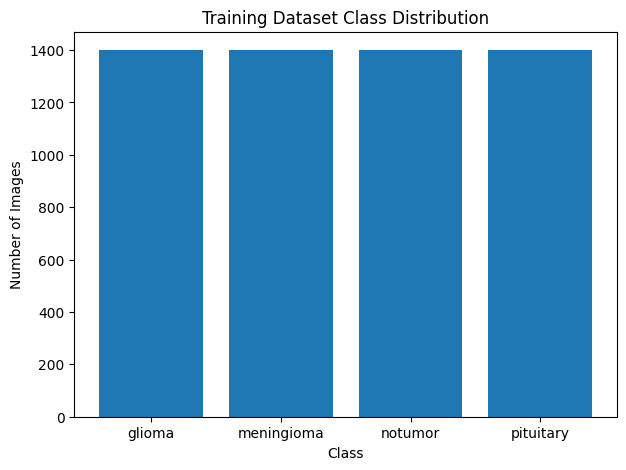

In [59]:
# class distribution plot

train_counts = [
    len(os.listdir(os.path.join(train_dir, cls)))
    for cls in class_names
]

plt.figure(figsize=(7,5))
plt.bar(class_names, train_counts)

plt.title("Training Dataset Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")

plt.show()

In [60]:
# The dataset is balanced.(only negligible difference)

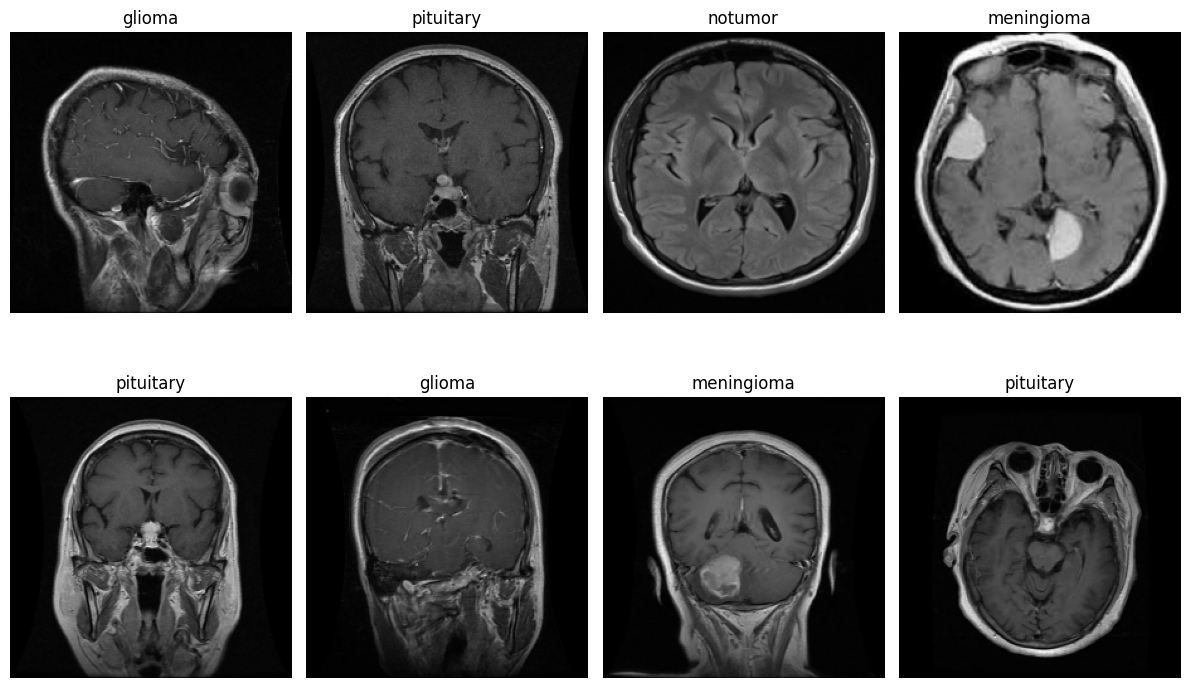

In [61]:
# Displaying Sample Images
images, labels = next(iter(train_dataset))

plt.figure(figsize=(12,8))

for i in range(8):
    plt.subplot(2,4,i+1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(class_names[labels[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [13]:
# Inference: Ensured that dataset labels corresponded to their respective class folders

In [62]:
images.shape

TensorShape([32, 224, 224, 3])

# Data Preprocessing

## Normalizing

In [63]:
# Before normalizing
images, labels = next(iter(train_dataset))
print("Minimum Pixel Value:", images.numpy().min())
print("Maximum Pixel Value:", images.numpy().max())

Minimum Pixel Value: 0.0
Maximum Pixel Value: 255.0


In [64]:
# Normalizing

normalization_layer = tf.keras.layers.Rescaling(1./255)

train_dataset = train_dataset.map(
    lambda x, y: (normalization_layer(x), y)
)

validation_dataset = validation_dataset.map(
    lambda x, y: (normalization_layer(x), y)
)

test_dataset = test_dataset.map(
    lambda x, y: (normalization_layer(x), y)
)

In [65]:
# After normalizing
images, labels = next(iter(train_dataset))
print("Minimum Pixel Value:", images.numpy().min())
print("Maximum Pixel Value:", images.numpy().max())

Minimum Pixel Value: 0.0
Maximum Pixel Value: 1.0


In [18]:
# Inference: The Rescaling(1./255) layer, the pixel values were normalized to the range 0 to 1

## Data Augmentation

In [66]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1)
])

In [20]:
# To increases image diversity, some random transformations are applied:

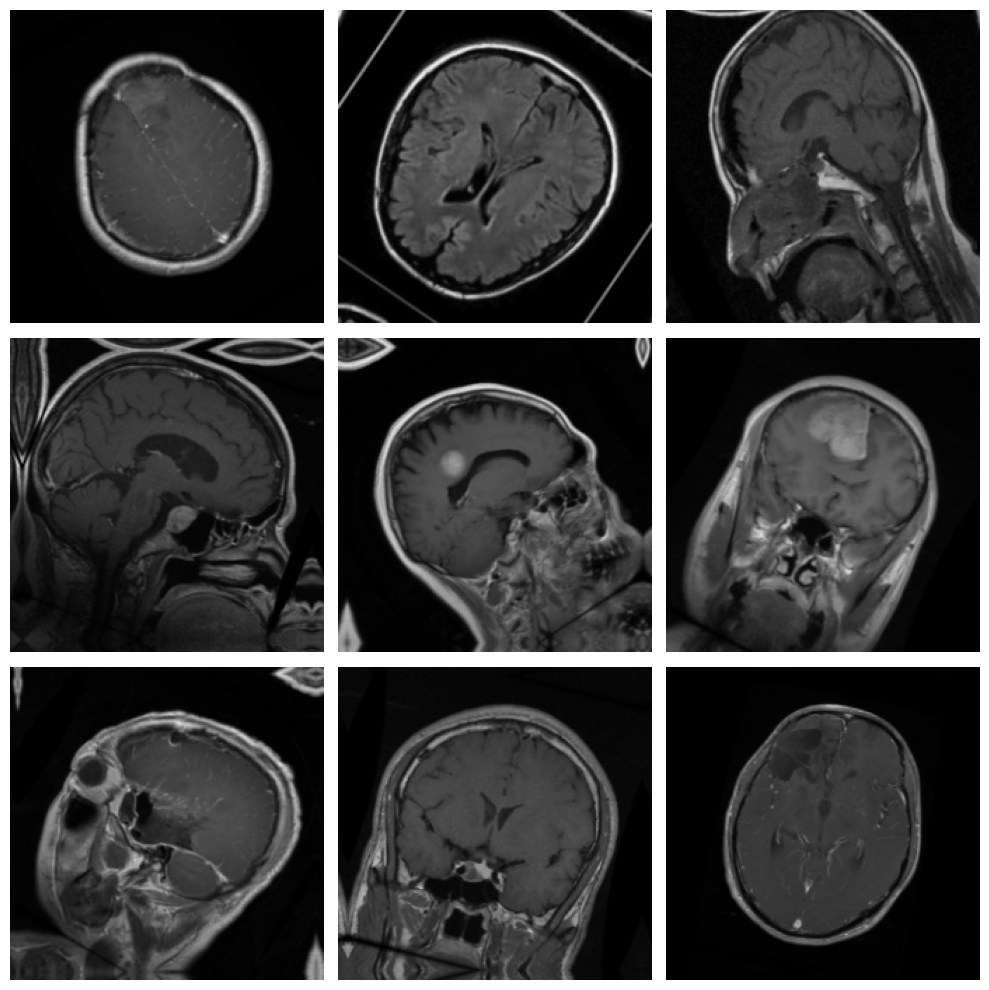

In [67]:
# Visualize augmented images
images, labels = next(iter(train_dataset))

plt.figure(figsize=(10,10))

for i in range(9):
    augmented_image = data_augmentation(images)[i]

    plt.subplot(3,3,i+1)
    plt.imshow(augmented_image.numpy())
    plt.axis("off")

plt.tight_layout()
plt.show()

# Model Building


In [68]:
# Building the CNN model

model = tf.keras.Sequential([

    tf.keras.layers.Conv2D(
        32, (3,3),
        activation='relu',
        input_shape=(IMG_HEIGHT, IMG_WIDTH,  3)
    ),
    tf.keras.layers.MaxPooling2D((2,2)),

    tf.keras.layers.Conv2D(
        64, (3,3),
        activation='relu'
    ),
    tf.keras.layers.MaxPooling2D((2,2)),

    tf.keras.layers.Conv2D(
        128, (3,3),
        activation='relu'
    ),
    tf.keras.layers.MaxPooling2D((2,2)),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(len(class_names), activation='softmax')

])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


## Compile Model

In [69]:
# Compile the CNN Model

model.compile(optimizer = 'adam',                         # Adam optimizer for efficient weight updates
              loss = 'sparse_categorical_crossentropy',   # Suitable for multi-class classification with integer labels
              metrics = ['accuracy'])                     # Tracks classification accuracy during training

## Train Model

In [70]:
# Begin Model Training

print("\n Started Training.....")


 Started Training.....


In [26]:
history = model.fit(train_dataset,
                    validation_data = test_dataset,
                    epochs = 10)

Epoch 1/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 1309s 7s/step - accuracy: 0.7325 - loss: 0.6813 - val_accuracy: 0.7775 - val_loss: 0.7367
Epoch 2/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 30s 167ms/step - accuracy: 0.8671 - loss: 0.3424 - val_accuracy: 0.8250 - val_loss: 0.7224
Epoch 3/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 43s 179ms/step - accuracy: 0.9216 - loss: 0.2099 - val_accuracy: 0.8525 - val_loss: 0.7834
Epoch 4/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 29s 166ms/step - accuracy: 0.9513 - loss: 0.1365 - val_accuracy: 0.8550 - val_loss: 0.7572
Epoch 5/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 31s 177ms/step - accuracy: 0.9598 - loss: 0.1130 - val_accuracy: 0.8825 - val_loss: 0.9085
Epoch 6/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 29s 166ms/step - accuracy: 0.9729 - loss: 0.0729 - val_accuracy: 0.8763 - val_loss: 1.0165
Epoch 7/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 43s 177ms/step - accuracy: 0.9823 - loss: 0.0525 - val_accuracy: 0.8931 - val_loss: 1.0973
Epoch 8/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 30s 169ms/step - accuracy: 0.9818 - loss: 0.

##Save Model

In [71]:
# Saving the CNN model

model.save("brain_tumor_cnn_v1.keras")

In [72]:
# Confirmation Message

print("\n Model saved as brain_tumor_cnn_v1.keras")


 Model saved as brain_tumor_cnn_v1.keras


## Plot Accuracy & Loss Graphs

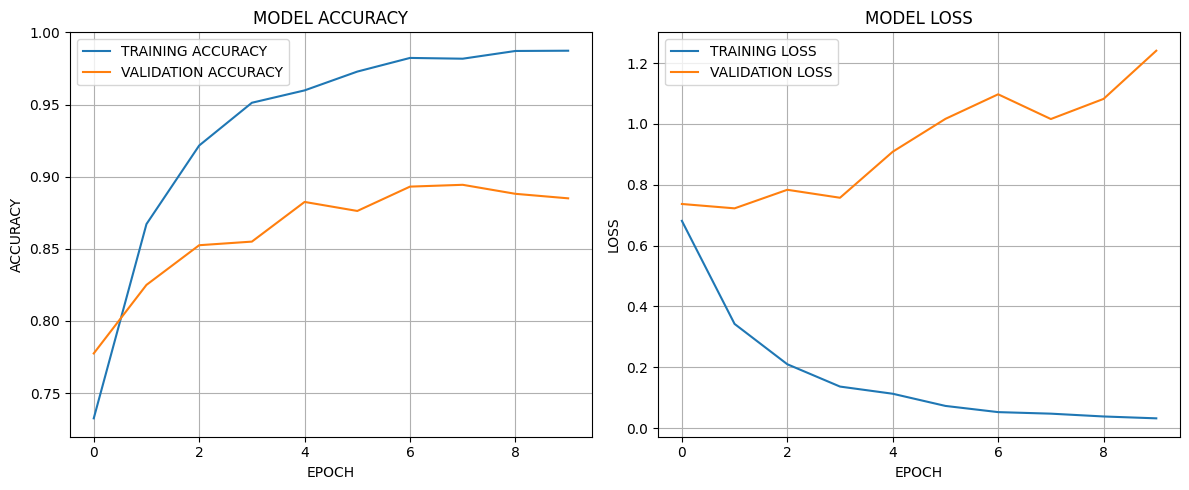

In [73]:
# Visualize Model Performance

plt.figure(figsize=(12,5))

# Accuracy Graph
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='TRAINING ACCURACY')
plt.plot(history.history['val_accuracy'], label='VALIDATION ACCURACY')
plt.title('MODEL ACCURACY')
plt.xlabel('EPOCH')
plt.ylabel('ACCURACY')
plt.legend()
plt.grid(True)

# Loss Graph
plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='TRAINING LOSS')
plt.plot(history.history['val_loss'], label='VALIDATION LOSS')
plt.title('MODEL LOSS')
plt.xlabel('EPOCH')
plt.ylabel('LOSS')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

## Predict Test Image

In [74]:
# Load the previously saved CNN model from the .keras file

model = tf.keras.models.load_model("brain_tumor_cnn_v1.keras")

/usr/local/lib/python3.12/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 22 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [75]:
# Search for the test image in Google Drive

!find

Streaming output truncated to the last 5000 lines.
./drive/MyDrive/Datasets/Brain_tumer_dataset_parallel_project/Training/glioma/Tr-gl_225.jpg
./drive/MyDrive/Datasets/Brain_tumer_dataset_parallel_project/Training/glioma/Tr-gl_687.jpg
./drive/MyDrive/Datasets/Brain_tumer_dataset_parallel_project/Training/glioma/Tr-gl_611.jpg
./drive/MyDrive/Datasets/Brain_tumer_dataset_parallel_project/Training/glioma/Tr-gl_1388.jpg
./drive/MyDrive/Datasets/Brain_tumer_dataset_parallel_project/Training/glioma/Tr-gl_655.jpg
./drive/MyDrive/Datasets/Brain_tumer_dataset_parallel_project/Training/glioma/Tr-gl_1187.jpg
./drive/MyDrive/Datasets/Brain_tumer_dataset_parallel_project/Training/glioma/Tr-gl_619.jpg
./drive/MyDrive/Datasets/Brain_tumer_dataset_parallel_project/Training/glioma/Tr-gl_404.jpg
./drive/MyDrive/Datasets/Brain_tumer_dataset_parallel_project/Training/glioma/Tr-gl_1398.jpg
./drive/MyDrive/Datasets/Brain_tumer_dataset_parallel_project/Training/glioma/Tr-gl_717.jpg
./drive/MyDrive/Datasets/B

In [45]:
# Define the file path of the image to be used for prediction.

test_image_path = "./drive/MyDrive/Datasets/Brain_tumer_dataset_parallel_project/Training/glioma/Tr-gl_225.jpg"

In [76]:
# Load and Preprocess Test Image

if not os.path.exists(test_image_path):
    raise FileNotFoundError(f"Test image not found: {test_image_path}")         # Check whether the test image exists


# Read image using OpenCv
image = cv2.imread(test_image_path)

# Original
display_image = image.copy()

# Resize for model
image = cv2.resize(image, (IMG_HEIGHT, IMG_WIDTH))

# Convert BRG to RGB
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Normalize
image = image/255.0

# Add batch dimension
image = np.expand_dims(image, axis = 0)

#Predict
prediction = model.predict(image)


predicted_index = np.argmax(prediction)
predicted_class = class_names[predicted_index]
confidence = np.max(prediction) * 100                                           # Predict Brain Tumor Class

print(f'\n Prediction: {predicted_class}')
print(f'\n Confidence: {confidence}')


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 374ms/step

 Prediction: meningioma

 Confidence: 26.318185806274414


##Display Result

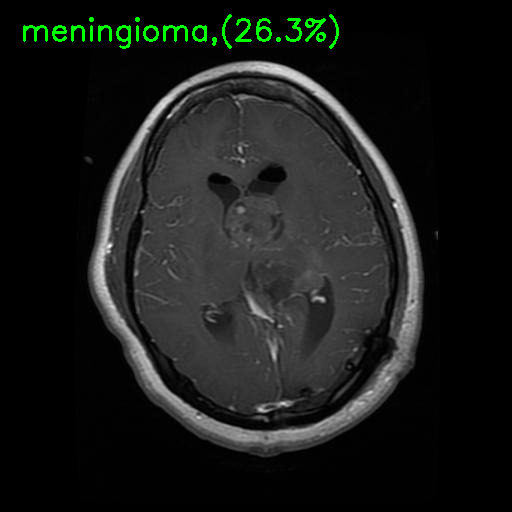

In [78]:
# Display Prediction on Image

text = f'{predicted_class},({confidence:.1f}%)'       # Create the prediction label with confidence score

cv2.putText(
    display_image,
    text,(20,40),
    cv2.FONT_HERSHEY_SIMPLEX,                         # Draw the prediction text on the image
    1,(0,255,0),
    2
)
cv2_imshow(display_image)                            # Display the predicted image